# Program annotation panels: regulators, marker genes, and motif enrichment

This notebook generates Illustrator-editable Day 0, Day 1, Day 2, and Day 3 program annotation panels with three side-by-side blocks:

1. **Regulator effects** from `cNMF_50_0_2_032526_6co.xlsx`, sheet `Perturbation Association 1`.
2. **Marker-gene cNMF consensus loadings** from the dt=0.2 consensus spectra matrix.
3. **Motif enrichment** from `enhancer_enrichment_results.tsv`, with motif logos drawn as vector logomaker glyphs directly from the MoDISco compiled CWM H5.

Outputs are written to:
`/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps`

The heatmap tiles are drawn as opaque vector rectangles to avoid Illustrator/Preview rendering differences. Motif logos are vector objects in the SVG/PDF. This is more editable in Illustrator but can make the files heavier.


**Updated version:** motif logos are drawn as vector logomaker glyphs, not raster PNGs.


**Updated complete-annotation behavior:** motif columns are selected as the top 3 motifs per program regardless of significance. Stars still indicate q-value/FDR thresholds, but non-significant top motifs remain visible.

## Cell 1 — imports, paths, and settings

In [1]:

import os
import re
import json
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import h5py
import logomaker

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable


# ============================================================
# INPUT PATHS
# ============================================================

CONSENSUS_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "spectra.k_50.dt_0_2.consensus.txt"
)

PROGRAM_ANNOT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps/data/Programs_annotations.xlsx"
)

CNMF_WORKBOOK_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx"
)

ENHANCER_ENRICHMENT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec/"
    "analysis/2.tf_enrichment_in_programs/enhancer_enrichment_results.tsv"
)

CLUSTER_MAP_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec/"
    "analysis/0.0.motif_id_annotation/tables/"
    "cluster_to_tf_motif_id_mapping.tsv"
)

MODISCO_H5_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec/"
    "results/compendium/modisco_compiled/modisco_compiled.h5"
)

OUTDIR = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps"
)

SOURCE_DIR = OUTDIR / "_program_annotation_source"
LOGO_DIR = OUTDIR / "_program_annotation_logo_cache"  # retained for compatibility; vector logos do not use this cache

OUTDIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
LOGO_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# FIGURE SETTINGS
# ============================================================

DAYS_TO_PLOT = ["D0", "D1", "D2", "D3"]

N_TOP_REGULATORS = 3
N_TOP_MOTIFS = 3

REGULATOR_FDR_THRESHOLD = 0.05
MOTIF_QVAL_THRESHOLD = 0.05

# Used only for matching rows in the consensus spectra matrix.
# "auto" tests offsets 0, +1, -1 using known marker genes.
PROGRAM_OFFSET = "auto"

# Vector motif logos requested: draw logomaker logos directly in the figure.
# This is more Illustrator-editable than raster PNG logos, but the SVG/PDF can be heavier.
VECTOR_LOGOS = True

# Optional manual overrides if cluster mapping column auto-detection fails.
MANUAL_CLUSTER_ID_COL = None
MANUAL_MOTIF_NAME_COLS = None  # example: ["tf", "motif", "motif_name"]


# Figure geometry
CELL_W = 0.34
CELL_H = 0.34
HEATMAP_GAP_IN = 0.65
LEFT_MARGIN_IN = 3.3
RIGHT_MARGIN_IN = 0.9
BOTTOM_MARGIN_IN = 2.25
TOP_MARGIN_IN = 2.0
TITLE_SPACE_IN = 0.55
CBAR_SPACE_IN = 0.35
CBAR_HEIGHT_IN = 0.16
MOTIF_LOGO_HEIGHT_IN = 0.55
MOTIF_LOGO_PAD_IN = 0.10
MOTIF_CBAR_ABOVE_LOGO_GAP_IN = 0.45
MOTIF_TITLE_ABOVE_CBAR_GAP_IN = 0.25

# Colormaps requested
REGULATOR_CMAP = mpl.colormaps["RdBu_r"]
MARKER_CMAP = mpl.colormaps["Greys"]
MOTIF_CMAP = mpl.colormaps["Purples"]


# Illustrator-safe matplotlib defaults
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.transparent": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
})

print("Output directory:", OUTDIR)


Matplotlib is building the font cache; this may take a moment.


Output directory: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps


## Cell 2 — metadata, regulator, and consensus-loading helper functions

In [2]:

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def normalize_token(x):
    if pd.isna(x):
        return None
    x = str(x).strip().upper()
    x = re.sub(r"[^A-Z0-9]+", "", x)
    return x if x else None


def parse_program_num(x):
    m = re.search(r"(\d+)", str(x))
    return int(m.group(1)) if m else None


def split_feature_text(x):
    """
    Split annotation strings like:
      'TAL1/FLI1'
      'MECOM; NRP1; EFNB2'
      'L1TD1, DPPA4, TERF1, SOX2'
    into ordered feature tokens.
    """
    if pd.isna(x):
        return []

    txt = str(x).strip()
    if txt == "":
        return []

    parts = re.split(r"[;,/]", txt)
    cleaned = []
    seen = set()

    for part in parts:
        item = str(part).strip()
        item = re.sub(r"\([^)]*\)", "", item).strip()
        item = item.replace("?", "").strip()
        item = re.sub(r"\s+", " ", item)
        if item == "":
            continue

        # keep first token if there are comments
        item = item.split(" ")[0].strip()
        key = normalize_token(item)

        if key and key not in seen:
            cleaned.append(item)
            seen.add(key)

    return cleaned


def star_text(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def read_matrix_flex(path, index_col=0):
    attempts = [
        {"sep": "\t"},
        {"sep": r"\s+", "engine": "python"},
        {"sep": ","},
    ]
    errors = []

    for kwargs in attempts:
        try:
            df = pd.read_csv(path, index_col=index_col, **kwargs)
            df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
            if df.shape[0] >= 2 and df.shape[1] >= 2:
                return df
        except Exception as e:
            errors.append(str(e))

    raise ValueError(
        f"Could not read matrix: {path}\n" + "\n".join(errors)
    )


# ============================================================
# CONSENSUS LOADING MATRIX
# ============================================================

def read_consensus_matrix(path):
    """
    Return consensus matrix oriented as programs x genes.
    """
    mat = read_matrix_flex(path, index_col=0)

    # likely already ~50 x many_genes
    if mat.shape[0] > 200 and mat.shape[1] <= 200:
        mat = mat.T
    elif not (mat.shape[0] <= 200 and mat.shape[1] > 200):
        idx_prog_frac = np.mean([
            bool(re.fullmatch(r"\s*(?:P|Program)?\s*\d+(?:\.0)?\s*", str(x), flags=re.I))
            for x in mat.index
        ])
        col_prog_frac = np.mean([
            bool(re.fullmatch(r"\s*(?:P|Program)?\s*\d+(?:\.0)?\s*", str(x), flags=re.I))
            for x in mat.columns
        ])
        if col_prog_frac > idx_prog_frac:
            mat = mat.T

    mat.columns = mat.columns.astype(str).str.strip()

    if mat.columns.duplicated().any():
        print("[warning] Duplicate gene columns found; collapsing by mean.")
        mat = mat.T.groupby(level=0).mean().T

    return mat.apply(pd.to_numeric, errors="coerce")


def build_program_row_lookup(consensus_df):
    lookup = {}
    for row_label in consensus_df.index:
        p = parse_program_num(row_label)
        if p is not None and p not in lookup:
            lookup[p] = row_label
    return lookup


def choose_program_offset(consensus_df, program_meta):
    """
    Use marker-gene loading consistency to choose offset 0 / +1 / -1.
    """
    if PROGRAM_OFFSET != "auto":
        print("Using manual PROGRAM_OFFSET =", PROGRAM_OFFSET)
        return int(PROGRAM_OFFSET)

    row_lookup = build_program_row_lookup(consensus_df)
    gene_lookup = {normalize_token(g): g for g in consensus_df.columns}

    def score_offset(offset):
        vals = []
        for _, row in program_meta.iterrows():
            p = int(row["program_num"])
            marker_genes = row["marker_genes"]
            raw_p = p + offset
            if raw_p not in row_lookup:
                continue
            raw_row = row_lookup[raw_p]
            for gene in marker_genes:
                g = gene_lookup.get(normalize_token(gene))
                if g is None:
                    continue
                val = consensus_df.loc[raw_row, g]
                if pd.notna(val):
                    vals.append(float(val))
        if len(vals) == 0:
            return -np.inf
        return float(np.mean(vals))

    scores = {off: score_offset(off) for off in [0, 1, -1]}
    print("Consensus program-offset scores:", scores)
    best = max(scores, key=scores.get)
    print("Chosen consensus program offset:", best)
    return best


# ============================================================
# PROGRAM METADATA
# ============================================================

def load_program_metadata():
    """
    Merge:
      Programs_annotations.xlsx: program labels + representative genes
      cNMF Summary: automatic timepoint + top specific regulators columns
    """
    # Programs_annotations.xlsx
    annot = pd.read_excel(PROGRAM_ANNOT_PATH)
    annot.columns = [str(c).strip() for c in annot.columns]

    # Auto-detect expected annotation columns
    prog_col = next((c for c in annot.columns if "program" in c.lower() and "number" in c.lower()), annot.columns[0])
    name_col = next((c for c in annot.columns if c.lower() in ["name", "program name"]), None)
    rep_col = next((c for c in annot.columns if "representative" in c.lower() and "gene" in c.lower()), None)

    if name_col is None:
        name_col = next((c for c in annot.columns if "name" in c.lower()), None)
    if rep_col is None:
        rep_col = next((c for c in annot.columns if "gene" in c.lower()), None)

    if name_col is None or rep_col is None:
        raise ValueError(
            "Could not detect Name / Representative genes columns in Programs_annotations.xlsx. "
            f"Columns: {annot.columns.tolist()}"
        )

    annot = annot.rename(columns={
        prog_col: "program_raw",
        name_col: "program_name",
        rep_col: "representative_genes",
    })
    annot["program_num"] = annot["program_raw"].map(parse_program_num)
    annot = annot.dropna(subset=["program_num"]).copy()
    annot["program_num"] = annot["program_num"].astype(int)
    annot["program_name"] = annot["program_name"].astype(str).str.strip()
    annot["marker_genes"] = annot["representative_genes"].map(split_feature_text)

    # cNMF Summary
    summary = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Summary")
    summary.columns = [str(c).strip() for c in summary.columns]
    summary = summary.rename(columns={
        "program_name": "program_num",
        "Automatic Timepoint": "day",
    })
    summary["program_num"] = summary["program_num"].map(parse_program_num)
    summary = summary.dropna(subset=["program_num"]).copy()
    summary["program_num"] = summary["program_num"].astype(int)
    summary["day"] = summary["day"].astype(str).str.strip().str.upper()

    # merge
    meta = annot.merge(summary, on="program_num", how="left")

    # label
    meta["row_label"] = meta.apply(
        lambda r: f"P{int(r['program_num'])}  {r['program_name']}",
        axis=1
    )

    meta["marker_gene_source"] = "Programs_annotations.xlsx"
    meta = meta.sort_values(["day", "program_num"]).reset_index(drop=True)

    return meta


# ============================================================
# REGULATORS
# ============================================================

def load_perturbation_associations():
    pert = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Perturbation Association 1")
    pert.columns = [str(c).strip() for c in pert.columns]

    rename = {}
    if "target_name" in pert.columns:
        rename["target_name"] = "gene"
    if "program_name" in pert.columns:
        rename["program_name"] = "program"
    if "Sample" in pert.columns:
        rename["Sample"] = "day"
    if "approx_log2FC" in pert.columns:
        rename["approx_log2FC"] = "log2fc"
    if "adj_pval" in pert.columns:
        rename["adj_pval"] = "fdr"

    # Alternate spellings
    if "Perturbed gene" in pert.columns:
        rename["Perturbed gene"] = "gene"
    if "Gene Program" in pert.columns:
        rename["Gene Program"] = "program"
    if "adj.P.Val" in pert.columns:
        rename["adj.P.Val"] = "fdr"

    pert = pert.rename(columns=rename)

    required = ["gene", "program", "day", "log2fc", "fdr"]
    missing = [c for c in required if c not in pert.columns]
    if missing:
        raise ValueError(
            f"Perturbation Association 1 missing columns after rename: {missing}\n"
            f"Available columns: {pert.columns.tolist()}"
        )

    pert["program_num"] = pert["program"].map(parse_program_num)
    pert["day"] = pert["day"].astype(str).str.strip().str.upper()
    pert["gene_display"] = pert["gene"].astype(str).str.strip()
    pert["gene_key"] = pert["gene_display"].map(normalize_token)
    pert["log2fc"] = pd.to_numeric(pert["log2fc"], errors="coerce")
    pert["fdr"] = pd.to_numeric(pert["fdr"], errors="coerce")
    pert["is_sig"] = pert["fdr"] < REGULATOR_FDR_THRESHOLD

    return pert


def select_top_regulators_for_programs(program_meta_day, pert):
    """
    Top 3 specific regulators per program:
      1) use cNMF Summary column: 'Top 5 specific regulators (FDR<0.1) D2/D3'
      2) keep first N_TOP_REGULATORS from that list
      3) retrieve log2FC/FDR from Perturbation Association 1
    """
    day = str(program_meta_day["day"].iloc[0]).upper()
    col = f"Top 5 specific regulators (FDR<0.1) {day}"
    if col not in program_meta_day.columns:
        raise ValueError(f"Missing Summary column: {col}")

    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        regulator_list = split_feature_text(prow.get(col, ""))[:N_TOP_REGULATORS]
        selected_by_program[p] = regulator_list

        for rank, gene in enumerate(regulator_list, start=1):
            sub = pert.loc[
                (pert["program_num"] == p)
                & (pert["day"] == day)
                & (pert["gene_key"] == normalize_token(gene))
            ].copy()

            if len(sub) == 0:
                log2fc = np.nan
                fdr = np.nan
            else:
                # If duplicated, keep lowest FDR
                sub = sub.sort_values("fdr")
                log2fc = sub["log2fc"].iloc[0]
                fdr = sub["fdr"].iloc[0]

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "gene": gene,
                "log2fc": log2fc,
                "fdr": fdr,
                "signif_star": star_text(fdr),
            })

    selected_df = pd.DataFrame(rows)

    # union across programs in program order
    union = []
    seen = set()
    for p in program_meta_day["program_num"]:
        for gene in selected_by_program[int(p)]:
            key = normalize_token(gene)
            if key not in seen:
                union.append(gene)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_regulator_matrices(program_meta_day, regulator_union, pert):
    day = str(program_meta_day["day"].iloc[0]).upper()
    rows = [int(x) for x in program_meta_day["program_num"]]

    sub = pert.loc[pert["day"] == day].copy()

    effect_pivot = sub.pivot_table(
        index="program_num",
        columns="gene_key",
        values="log2fc",
        aggfunc="first"
    )
    fdr_pivot = sub.pivot_table(
        index="program_num",
        columns="gene_key",
        values="fdr",
        aggfunc="min"
    )

    reg_keys = [normalize_token(g) for g in regulator_union]

    effect_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=float)
    fdr_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=float)
    star_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=object)

    for disp, key in zip(regulator_union, reg_keys):
        for p in rows:
            val = np.nan
            q = np.nan
            if p in effect_pivot.index and key in effect_pivot.columns:
                val = effect_pivot.loc[p, key]
            if p in fdr_pivot.index and key in fdr_pivot.columns:
                q = fdr_pivot.loc[p, key]

            effect_mat.loc[p, disp] = val
            fdr_mat.loc[p, disp] = q
            star_mat.loc[p, disp] = star_text(q)

    return effect_mat, fdr_mat, star_mat


## Cell 3 — marker-gene, motif, and vector-logo helper functions

In [3]:

# ============================================================
# MARKER GENES AND MOTIFS
# ============================================================

def select_marker_genes_for_programs(program_meta_day):
    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        genes = list(prow["marker_genes"])
        selected_by_program[p] = genes

        for rank, gene in enumerate(genes, start=1):
            rows.append({
                "day": prow["day"],
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "gene": gene,
                "source": prow["marker_gene_source"],
            })

    selected_df = pd.DataFrame(rows)

    union = []
    seen = set()
    for p in program_meta_day["program_num"]:
        for gene in selected_by_program[int(p)]:
            key = normalize_token(gene)
            if key not in seen:
                union.append(gene)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_marker_loading_matrix(program_meta_day, marker_union, consensus_df, consensus_offset):
    row_lookup = build_program_row_lookup(consensus_df)
    gene_lookup = {normalize_token(g): g for g in consensus_df.columns}

    rows = [int(x) for x in program_meta_day["program_num"]]
    mat = pd.DataFrame(index=rows, columns=marker_union, dtype=float)

    for p in rows:
        raw_p = p + consensus_offset
        if raw_p not in row_lookup:
            continue
        raw_row = row_lookup[raw_p]

        for gene in marker_union:
            g = gene_lookup.get(normalize_token(gene))
            if g is not None:
                mat.loc[p, gene] = consensus_df.loc[raw_row, g]

    return mat


def load_enhancer_enrichment():
    df = pd.read_csv(ENHANCER_ENRICHMENT_PATH, sep="\t")
    df["program_num"] = pd.to_numeric(df["program"], errors="coerce").astype("Int64")
    df["tf_display"] = df["tf"].astype(str).str.strip()
    df["tf_key"] = df["tf_display"].map(normalize_token)
    df["day"] = df["day"].astype(str).str.strip().str.upper()
    df["qval"] = pd.to_numeric(df["qval"], errors="coerce")
    df["neg_log10_qval"] = pd.to_numeric(df["neg_log10_qval"], errors="coerce")
    return df


def select_top_motifs_for_programs(program_meta_day, enrich):
    """
    Complete annotation-panel motif selection.

    For every program:
      - select the top N_TOP_MOTIFS motifs by q-value
      - do NOT require q < MOTIF_QVAL_THRESHOLD
      - keep non-significant motifs in the figure
      - use stars only to mark significance

    This guarantees that programs such as P7/P22 at D0 and P28 at D1
    still contribute motif columns/logos even when no motif passes q < 0.05.
    """
    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        day = str(prow["day"]).strip().upper()

        sub = enrich.loc[
            (enrich["program_num"] == p)
            & (enrich["day"] == day)
        ].copy()

        if sub.empty:
            selected_by_program[p] = []

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": np.nan,
                "motif": np.nan,
                "qval": np.nan,
                "neg_log10_qval": np.nan,
                "AUC": np.nan,
                "significant": False,
                "signif_star": "",
                "note": "no motif enrichment rows found",
            })

            continue

        # Make sure numeric columns are numeric
        sub["qval"] = pd.to_numeric(sub["qval"], errors="coerce")
        sub["neg_log10_qval"] = pd.to_numeric(sub["neg_log10_qval"], errors="coerce")

        if "AUC" in sub.columns:
            sub["AUC"] = pd.to_numeric(sub["AUC"], errors="coerce")
        else:
            sub["AUC"] = np.nan

        # Deduplicate motifs, keeping strongest q-value
        sub = (
            sub.sort_values(
                by=["qval", "neg_log10_qval", "AUC"],
                ascending=[True, False, False],
            )
            .drop_duplicates("tf_key", keep="first")
        )

        # Complete-panel behavior:
        # take top motifs regardless of significance
        top = sub.head(N_TOP_MOTIFS).copy()

        motifs = top["tf_display"].tolist()
        selected_by_program[p] = motifs

        for rank, (_, r) in enumerate(top.iterrows(), start=1):
            q = r["qval"]

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "motif": r["tf_display"],
                "qval": q,
                "neg_log10_qval": r["neg_log10_qval"],
                "AUC": r.get("AUC", np.nan),
                "significant": bool(pd.notna(q) and q < MOTIF_QVAL_THRESHOLD),
                "signif_star": star_text(q),
                "note": "top motif by q-value; significance not required",
            })

    selected_df = pd.DataFrame(rows)

    # Union motifs across programs in program order
    union = []
    seen = set()

    for p in program_meta_day["program_num"]:
        for motif in selected_by_program.get(int(p), []):
            key = normalize_token(motif)

            if key not in seen:
                union.append(motif)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_motif_matrices(program_meta_day, motif_union, enrich):
    rows = [int(x) for x in program_meta_day["program_num"]]
    day = str(program_meta_day["day"].iloc[0]).upper()
    sub = enrich.loc[enrich["day"] == day].copy()

    value_pivot = sub.pivot_table(
        index="program_num",
        columns="tf_key",
        values="neg_log10_qval",
        aggfunc="first"
    )
    qval_pivot = sub.pivot_table(
        index="program_num",
        columns="tf_key",
        values="qval",
        aggfunc="min"
    )

    motif_keys = [normalize_token(m) for m in motif_union]

    value_mat = pd.DataFrame(index=rows, columns=motif_union, dtype=float)
    qval_mat = pd.DataFrame(index=rows, columns=motif_union, dtype=float)
    star_mat = pd.DataFrame(index=rows, columns=motif_union, dtype=object)

    for disp, key in zip(motif_union, motif_keys):
        for p in rows:
            val = np.nan
            qv = np.nan

            if p in value_pivot.index and key in value_pivot.columns:
                val = value_pivot.loc[p, key]
            if p in qval_pivot.index and key in qval_pivot.columns:
                qv = qval_pivot.loc[p, key]

            value_mat.loc[p, disp] = val
            qval_mat.loc[p, disp] = qv
            star_mat.loc[p, disp] = star_text(qv)

    return value_mat, qval_mat, star_mat



# ============================================================
# MOTIF LOGOS: vector logomaker glyphs
# ============================================================

def infer_cluster_map_columns(df):
    if MANUAL_CLUSTER_ID_COL is not None:
        id_col = MANUAL_CLUSTER_ID_COL
    else:
        candidates = []
        for c in df.columns:
            lc = c.lower()
            numeric_frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
            if numeric_frac > 0.80 and re.search(r"(cluster|pattern|cid|id)", lc):
                candidates.append(c)
        if not candidates:
            for c in df.columns:
                numeric_frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
                if numeric_frac > 0.80:
                    candidates.append(c)
        if len(candidates) == 0:
            raise ValueError(
                "Could not auto-detect cluster ID column. "
                f"Available columns: {list(df.columns)}"
            )
        id_col = candidates[0]

    if MANUAL_MOTIF_NAME_COLS is not None:
        name_cols = list(MANUAL_MOTIF_NAME_COLS)
    else:
        name_cols = []
        for c in df.columns:
            if c == id_col:
                continue
            if df[c].dtype == object:
                if not re.search(r"(path|file|url|image)", c.lower()):
                    name_cols.append(c)
        if len(name_cols) == 0:
            raise ValueError(
                "Could not auto-detect motif name columns. "
                f"Available columns: {list(df.columns)}"
            )

    return id_col, name_cols


def motif_alias_variants(name):
    base = str(name).strip()
    variants = set([base])

    cleaned = re.sub(r"_[0-9]+_$", "", base)
    variants.add(cleaned)

    for x in list(variants):
        variants.add(x.replace("_", ""))
        variants.add(x.replace("-", ""))
        variants.add(x.replace("/", ""))

    for part in re.split(r"[;/|]", base):
        part = part.strip()
        if part:
            variants.add(part)

    return [v for v in variants if v]


def build_cluster_lookup(cluster_map_df):
    id_col, name_cols = infer_cluster_map_columns(cluster_map_df)
    print("Cluster-map ID column:", id_col)
    print("Cluster-map motif columns:", name_cols)

    alias_to_cluster = {}

    for _, row in cluster_map_df.iterrows():
        cid = pd.to_numeric(row[id_col], errors="coerce")
        if pd.isna(cid):
            continue
        cid = int(cid)

        aliases = set()
        for c in name_cols:
            val = row[c]
            if pd.isna(val):
                continue
            aliases.add(str(val))
            for tok in re.split(r"[;,/|]", str(val)):
                tok = tok.strip()
                if tok:
                    aliases.add(tok)

        for alias in aliases:
            key = normalize_token(alias)
            if key and key not in alias_to_cluster:
                alias_to_cluster[key] = cid

    return alias_to_cluster


def best_cluster_for_motif(motif_name, alias_to_cluster):
    # exact match on normalized variants
    for variant in motif_alias_variants(motif_name):
        key = normalize_token(variant)
        if key in alias_to_cluster:
            return alias_to_cluster[key]

    # fuzzy prefix/containment match
    motif_keys = [normalize_token(v) for v in motif_alias_variants(motif_name)]
    motif_keys = [k for k in motif_keys if k]

    for mk in motif_keys:
        matches = []
        for alias_key, cid in alias_to_cluster.items():
            if mk.startswith(alias_key) or alias_key.startswith(mk):
                matches.append((len(alias_key), cid))
        if matches:
            matches = sorted(matches, reverse=True)
            return matches[0][1]

    return None


def load_cluster_cwms(h5_path):
    cluster_cwms = {}
    with h5py.File(h5_path, "r") as f:
        for cid_str in f["pos_patterns"].keys():
            cluster_cwms[int(cid_str)] = f["pos_patterns"][cid_str]["contrib_scores"][:]
    return cluster_cwms


def cwm_to_df(cwm):
    arr = np.asarray(cwm)
    if arr.ndim != 2:
        raise ValueError(f"Unexpected CWM ndim: {arr.ndim}")

    if arr.shape[1] == 4:
        mat = arr
    elif arr.shape[0] == 4:
        mat = arr.T
    else:
        raise ValueError(f"Unexpected CWM shape: {arr.shape}")

    return pd.DataFrame(mat, columns=list("ACGT"))


def resolve_logo_paths_for_motifs(motif_names):
    """
    Backward-compatible function name.

    Returns:
      motif_to_logo: dict motif -> {"type": "cwm", "cwm_df": DataFrame, "cluster_id": int}
                            or {"type": "text", "label": motif}
      motif_map_df:  metadata table with matched cluster IDs and status.

    Unlike the earlier raster version, this does NOT create PNG files.
    Logos are drawn as vector logomaker glyphs in add_logo_strip().
    """
    cluster_map_df = pd.read_csv(CLUSTER_MAP_PATH, sep="\t")
    alias_to_cluster = build_cluster_lookup(cluster_map_df)
    cluster_cwms = load_cluster_cwms(MODISCO_H5_PATH)

    motif_to_logo = {}
    motif_rows = []

    for motif in motif_names:
        cluster_id = best_cluster_for_motif(motif, alias_to_cluster)

        if cluster_id is not None and cluster_id in cluster_cwms:
            try:
                cwm_df = cwm_to_df(cluster_cwms[cluster_id])
                motif_to_logo[motif] = {
                    "type": "cwm",
                    "cwm_df": cwm_df,
                    "cluster_id": cluster_id,
                    "label": motif,
                }
                status = "vector_cwm"
            except Exception as e:
                print(f"[warning] Failed to load CWM for {motif} / cluster {cluster_id}: {e}")
                motif_to_logo[motif] = {"type": "text", "label": motif, "cluster_id": cluster_id}
                status = "text_fallback_after_cwm_error"
        else:
            motif_to_logo[motif] = {"type": "text", "label": motif, "cluster_id": cluster_id}
            status = "text_fallback_no_cluster"

        motif_rows.append({
            "motif": motif,
            "matched_cluster_id": cluster_id,
            "status": status,
        })

    motif_map_df = pd.DataFrame(motif_rows)
    return motif_to_logo, motif_map_df



## Cell 4 — plotting functions

In [4]:

# ============================================================
# PLOTTING FUNCTIONS
# ============================================================

def text_color_for_value(val, cmap, norm, na_color="#000000"):
    if pd.isna(val):
        return na_color
    rgba = cmap(norm(val))
    lum = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    return "white" if lum < 0.48 else "black"


def draw_rect_heatmap(
    ax,
    data_df,
    cmap,
    norm,
    xlabels,
    ylabels=None,
    stars_df=None,
    xlab_rotation=60,
    italic_x=False,
    show_ylabels=True,
    xlab_fontsize=8,
    ylab_fontsize=8,
    star_fontsize=7,
    edgecolor="white",
    linewidth=1.0,
    missing_color=(0.95, 0.95, 0.95, 1.0),
):
    n_rows, n_cols = data_df.shape
    vals = data_df.to_numpy(dtype=float)

    for i in range(n_rows):
        for j in range(n_cols):
            val = vals[i, j]
            if pd.isna(val):
                face = missing_color
            else:
                rgba = cmap(norm(val))
                face = (rgba[0], rgba[1], rgba[2], 1.0)

            ax.add_patch(
                Rectangle(
                    (j, i), 1, 1,
                    facecolor=face,
                    edgecolor=edgecolor,
                    linewidth=linewidth,
                )
            )

            if stars_df is not None:
                txt = stars_df.iloc[i, j]
                if isinstance(txt, str) and txt != "":
                    ax.text(
                        j + 0.5,
                        i + 0.5,
                        txt,
                        ha="center",
                        va="center",
                        fontsize=star_fontsize,
                        fontweight="bold",
                        color=text_color_for_value(val, cmap, norm),
                    )

    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_aspect("equal")

    ax.set_xticks(np.arange(n_cols) + 0.5)
    ax.set_xticklabels(
        xlabels,
        rotation=xlab_rotation,
        ha="right",
        rotation_mode="anchor",
        fontsize=xlab_fontsize,
        fontstyle="italic" if italic_x else "normal",
    )

    if show_ylabels:
        ax.set_yticks(np.arange(n_rows) + 0.5)
        ax.set_yticklabels(ylabels, fontsize=ylab_fontsize)
    else:
        ax.set_yticks(np.arange(n_rows) + 0.5)
        ax.set_yticklabels([""] * n_rows)

    ax.tick_params(axis="both", length=0, pad=4)

    for sp in ax.spines.values():
        sp.set_visible(False)


def add_horizontal_colorbar(fig, left, bottom, width, cmap, norm, label, ticksize=8, labelsize=9):
    cax = fig.add_axes([left, bottom, width, CBAR_HEIGHT_IN / fig.get_figheight()])
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.outline.set_linewidth(0.8)
    cb.ax.tick_params(labelsize=ticksize, length=2)
    cb.set_label(label, fontsize=labelsize, labelpad=2)
    return cax, cb


def add_logo_strip(fig, heat_ax, motif_names, motif_to_logo, logo_height_in=MOTIF_LOGO_HEIGHT_IN):
    """
    Place vector logomaker logos above each motif column.

    This replaces the raster-logo version. Logos remain editable in SVG/PDF,
    but the output files can be heavier because every letter is a vector path.
    """
    fig_h = fig.get_figheight()
    pos = heat_ax.get_position()
    x0, y0, w, h = pos.x0, pos.y0, pos.width, pos.height
    n_cols = len(motif_names)
    if n_cols == 0:
        return []

    col_w = w / n_cols
    logo_h = logo_height_in / fig_h
    logo_y = y0 + h + (MOTIF_LOGO_PAD_IN / fig_h)

    axes = []
    for j, motif in enumerate(motif_names):
        logo_x = x0 + j * col_w + col_w * 0.03
        logo_w = col_w * 0.94

        ax = fig.add_axes([logo_x, logo_y, logo_w, logo_h])
        logo_obj = motif_to_logo.get(motif, {"type": "text", "label": motif})

        if logo_obj.get("type") == "cwm":
            try:
                logomaker.Logo(
                    logo_obj["cwm_df"],
                    ax=ax,
                    color_scheme="classic",
                    fade_below=0.0,
                    shade_below=0.0,
                    font_name="DejaVu Sans",
                )
                ax.set_xticks([])
                ax.set_yticks([])
                ax.set_xlabel("")
                ax.set_ylabel("")
                ax.set_title("")
                for sp in ax.spines.values():
                    sp.set_visible(False)
            except Exception as e:
                print(f"[warning] Could not draw vector logo for {motif}: {e}")
                ax.text(0.5, 0.5, str(motif), ha="center", va="center", fontsize=7, fontweight="bold")
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.axis("off")
        else:
            ax.text(0.5, 0.5, str(logo_obj.get("label", motif)), ha="center", va="center", fontsize=7, fontweight="bold")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.axis("off")

        axes.append(ax)

    return axes


def make_day_panel(
    day,
    program_meta_day,
    regulator_effects,
    regulator_stars,
    marker_loadings,
    motif_values,
    motif_stars,
    motif_to_logo,
    regulator_union,
    marker_union,
    motif_union,
):
    row_labels = program_meta_day["row_label"].tolist()
    program_nums = program_meta_day["program_num"].tolist()

    reg_mat = regulator_effects.loc[program_nums, regulator_union]
    reg_star = regulator_stars.loc[program_nums, regulator_union]
    mark_mat = marker_loadings.loc[program_nums, marker_union]
    motif_mat = motif_values.loc[program_nums, motif_union]
    motif_star = motif_stars.loc[program_nums, motif_union]

    # norms
    reg_vals = reg_mat.to_numpy(dtype=float)
    reg_finite = reg_vals[np.isfinite(reg_vals)]
    reg_maxabs = max(1e-6, float(np.nanmax(np.abs(reg_finite)))) if reg_finite.size else 1.0
    reg_norm = TwoSlopeNorm(vmin=-reg_maxabs, vcenter=0.0, vmax=reg_maxabs)

    mark_vals = mark_mat.to_numpy(dtype=float)
    mark_finite = mark_vals[np.isfinite(mark_vals)]
    mark_vmax = max(1e-6, float(np.nanmax(mark_finite))) if mark_finite.size else 1.0
    mark_norm = Normalize(vmin=0.0, vmax=mark_vmax)

    motif_vals = motif_mat.to_numpy(dtype=float)
    motif_finite = motif_vals[np.isfinite(motif_vals)]
    motif_vmax = max(1e-6, float(np.nanmax(motif_finite))) if motif_finite.size else 1.0
    motif_norm = Normalize(vmin=0.0, vmax=motif_vmax)

    # dimensions
    n_rows = len(program_nums)
    n_reg = len(regulator_union)
    n_mark = len(marker_union)
    n_motif = len(motif_union)

    reg_w_in = max(2.2, n_reg * CELL_W)
    mark_w_in = max(2.2, n_mark * CELL_W)
    motif_w_in = max(2.2, n_motif * CELL_W)
    heat_h_in = max(3.0, n_rows * CELL_H)

    fig_w = (
        LEFT_MARGIN_IN
        + reg_w_in
        + HEATMAP_GAP_IN
        + mark_w_in
        + HEATMAP_GAP_IN
        + motif_w_in
        + RIGHT_MARGIN_IN
    )
    fig_h = (
        BOTTOM_MARGIN_IN
        + heat_h_in
        + MOTIF_LOGO_PAD_IN
        + MOTIF_LOGO_HEIGHT_IN
        + MOTIF_CBAR_ABOVE_LOGO_GAP_IN
        + CBAR_HEIGHT_IN
        + MOTIF_TITLE_ABOVE_CBAR_GAP_IN
        + TITLE_SPACE_IN
        + TOP_MARGIN_IN
    )

    fig = plt.figure(figsize=(fig_w, fig_h), facecolor="white")

    def fx(x): return x / fig_w
    def fy(y): return y / fig_h

    heat_bottom = BOTTOM_MARGIN_IN
    heat_left_1 = LEFT_MARGIN_IN
    heat_left_2 = heat_left_1 + reg_w_in + HEATMAP_GAP_IN
    heat_left_3 = heat_left_2 + mark_w_in + HEATMAP_GAP_IN

    ax_reg = fig.add_axes([fx(heat_left_1), fy(heat_bottom), fx(reg_w_in), fy(heat_h_in)])
    ax_mark = fig.add_axes([fx(heat_left_2), fy(heat_bottom), fx(mark_w_in), fy(heat_h_in)])
    ax_motif = fig.add_axes([fx(heat_left_3), fy(heat_bottom), fx(motif_w_in), fy(heat_h_in)])

    ylab_fs = max(6, min(13, 170 / max(n_rows, 1)))
    reg_x_fs = max(5, min(10, 220 / max(n_reg, 1)))
    mark_x_fs = max(5, min(10, 220 / max(n_mark, 1)))
    motif_x_fs = max(5, min(10, 220 / max(n_motif, 1)))
    star_fs = max(4, min(8, 170 / max(n_rows, 1)))

    draw_rect_heatmap(
        ax_reg, reg_mat, REGULATOR_CMAP, reg_norm,
        xlabels=regulator_union, ylabels=row_labels, stars_df=reg_star,
        italic_x=False, show_ylabels=True,
        xlab_fontsize=reg_x_fs, ylab_fontsize=ylab_fs, star_fontsize=star_fs,
    )

    draw_rect_heatmap(
        ax_mark, mark_mat, MARKER_CMAP, mark_norm,
        xlabels=marker_union, ylabels=row_labels, stars_df=None,
        italic_x=True, show_ylabels=False,
        xlab_fontsize=mark_x_fs, ylab_fontsize=ylab_fs, star_fontsize=star_fs,
    )

    draw_rect_heatmap(
        ax_motif, motif_mat, MOTIF_CMAP, motif_norm,
        xlabels=motif_union, ylabels=row_labels, stars_df=motif_star,
        italic_x=False, show_ylabels=False,
        xlab_fontsize=motif_x_fs, ylab_fontsize=ylab_fs, star_fontsize=star_fs,
    )

    # ------------------------------------------------------------------
    # Colorbar / title layout
    #
    # Regulator and marker colorbars sit above their heatmaps.
    # Motif logos sit immediately above the motif heatmap.
    # Motif enrichment color scale is pushed substantially above the logos
    # to avoid overlap in Illustrator/Preview.
    # ------------------------------------------------------------------
    reg_marker_cbar_y = heat_bottom + heat_h_in + 0.25
    reg_marker_title_y = reg_marker_cbar_y + CBAR_HEIGHT_IN + 0.30

    logo_y = heat_bottom + heat_h_in + MOTIF_LOGO_PAD_IN
    motif_cbar_y = logo_y + MOTIF_LOGO_HEIGHT_IN + MOTIF_CBAR_ABOVE_LOGO_GAP_IN
    motif_title_y = motif_cbar_y + CBAR_HEIGHT_IN + MOTIF_TITLE_ABOVE_CBAR_GAP_IN

    add_horizontal_colorbar(
        fig, fx(heat_left_1), fy(reg_marker_cbar_y), fx(reg_w_in),
        REGULATOR_CMAP, reg_norm, "log$_2$FC",
        ticksize=8, labelsize=10
    )
    add_horizontal_colorbar(
        fig, fx(heat_left_2), fy(reg_marker_cbar_y), fx(mark_w_in),
        MARKER_CMAP, mark_norm, "cNMF gene loading",
        ticksize=8, labelsize=10
    )
    add_horizontal_colorbar(
        fig, fx(heat_left_3), fy(motif_cbar_y), fx(motif_w_in),
        MOTIF_CMAP, motif_norm, "Motif enrichment",
        ticksize=8, labelsize=10
    )

    # Block titles
    fig.text(fx(heat_left_1 + reg_w_in / 2), fy(reg_marker_title_y), "Regulator effects",
             ha="center", va="bottom", fontsize=16)
    fig.text(fx(heat_left_2 + mark_w_in / 2), fy(reg_marker_title_y), "Marker genes",
             ha="center", va="bottom", fontsize=16)
    fig.text(
        fx(heat_left_3 + motif_w_in / 2),
        fy(motif_title_y),
        "Motif enrichment\n(top 3 per program)",
        ha="center",
        va="bottom",
        fontsize=16,
    )

    # Motif logo row
    add_logo_strip(fig, ax_motif, motif_union, motif_to_logo)

    # Day title and star legend
    day_title_map = {"D0": "Day 0", "D1": "Day 1", "D2": "Day 2", "D3": "Day 3"}
    day_title = day_title_map.get(day, str(day))
    fig.text(fx(0.55), fy(fig_h - 0.52), day_title, ha="left", va="top", fontsize=28)

    fig.text(
        fx(heat_left_1 + reg_w_in * 0.45),
        fy(fig_h - 0.62),
        "* FDR < 0.05\n** FDR < 0.01\n*** FDR < 0.001",
        ha="left",
        va="top",
        fontsize=12,
    )

    fig.text(
        fx(heat_left_3),
        fy(0.45),
        "Motifs shown regardless of significance; stars mark q-value thresholds.",
        fontsize=8.5,
        color="#444444",
        ha="left",
        va="bottom",
    )

    # Save
    outstem = OUTDIR / f"Program_annotation_panel_{day}"
    for ext in ["svg", "pdf", "png"]:
        save_kwargs = dict(bbox_inches="tight", facecolor="white", transparent=False)
        if ext == "png":
            save_kwargs["dpi"] = 600
        fig.savefig(outstem.with_suffix(f".{ext}"), **save_kwargs)

    plt.show()
    plt.close(fig)

    return outstem


## Cell 5 — load data, select features, and save source tables

In [5]:

# ============================================================
# LOAD DATA, SELECT FEATURES, SAVE SOURCE TABLES
# ============================================================

program_meta = load_program_metadata()
pert = load_perturbation_associations()
enh = load_enhancer_enrichment()
consensus = read_consensus_matrix(CONSENSUS_PATH)

print("Program metadata:", program_meta.shape)
print("Perturb associations:", pert.shape)
print("Enhancer enrichment:", enh.shape)
print("Consensus matrix:", consensus.shape)

# choose program offset for consensus matrix
consensus_offset = choose_program_offset(consensus, program_meta)

program_meta.to_csv(SOURCE_DIR / "program_metadata_merged.csv", index=False)

day_packages = {}

for day in DAYS_TO_PLOT:
    meta_day = (
        program_meta.loc[program_meta["day"] == day]
        .sort_values("program_num")
        .reset_index(drop=True)
    )

    if meta_day.empty:
        print(f"[warning] no programs found for {day}")
        continue

    # regulators
    reg_by_prog, reg_union, reg_selected_df = select_top_regulators_for_programs(meta_day, pert)
    reg_effect_mat, reg_fdr_mat, reg_star_mat = build_regulator_matrices(meta_day, reg_union, pert)

    # markers
    marker_by_prog, marker_union, marker_selected_df = select_marker_genes_for_programs(meta_day)
    marker_loading_mat = build_marker_loading_matrix(meta_day, marker_union, consensus, consensus_offset)

    # motifs
    motif_by_prog, motif_union, motif_selected_df = select_top_motifs_for_programs(meta_day, enh)
    motif_value_mat, motif_qval_mat, motif_star_mat = build_motif_matrices(meta_day, motif_union, enh)

    # logos
    motif_to_logo, motif_logo_map_df = resolve_logo_paths_for_motifs(motif_union)

    day_packages[day] = {
        "meta": meta_day,
        "reg_union": reg_union,
        "reg_selected_df": reg_selected_df,
        "reg_effect_mat": reg_effect_mat,
        "reg_fdr_mat": reg_fdr_mat,
        "reg_star_mat": reg_star_mat,
        "marker_union": marker_union,
        "marker_selected_df": marker_selected_df,
        "marker_loading_mat": marker_loading_mat,
        "motif_union": motif_union,
        "motif_selected_df": motif_selected_df,
        "motif_value_mat": motif_value_mat,
        "motif_qval_mat": motif_qval_mat,
        "motif_star_mat": motif_star_mat,
        "motif_to_logo": motif_to_logo,
        "motif_logo_map_df": motif_logo_map_df,
    }

    # Save source tables
    prefix = SOURCE_DIR / f"{day}"

    meta_day.to_csv(f"{prefix}_programs.csv", index=False)

    reg_selected_df.to_csv(f"{prefix}_selected_regulators.csv", index=False)
    reg_effect_mat.to_csv(f"{prefix}_regulator_effect_matrix.csv", index_label="program_num")
    reg_fdr_mat.to_csv(f"{prefix}_regulator_fdr_matrix.csv", index_label="program_num")
    reg_star_mat.to_csv(f"{prefix}_regulator_star_matrix.csv", index_label="program_num")

    marker_selected_df.to_csv(f"{prefix}_selected_marker_genes.csv", index=False)
    marker_loading_mat.to_csv(f"{prefix}_marker_loading_matrix.csv", index_label="program_num")

    motif_selected_df.to_csv(f"{prefix}_selected_motifs.csv", index=False)
    motif_value_mat.to_csv(f"{prefix}_motif_enrichment_matrix.csv", index_label="program_num")
    motif_qval_mat.to_csv(f"{prefix}_motif_qval_matrix.csv", index_label="program_num")
    motif_star_mat.to_csv(f"{prefix}_motif_star_matrix.csv", index_label="program_num")
    motif_logo_map_df.to_csv(f"{prefix}_motif_logo_map.csv", index=False)

    print(f"\n=== {day} ===")
    print("Programs:", meta_day["program_num"].tolist())
    print("Selected regulators:", len(reg_union))
    print("Selected marker genes:", len(marker_union))
    print("Selected motifs:", len(motif_union))

# Save config
config_used = {
    "CONSENSUS_PATH": str(CONSENSUS_PATH),
    "PROGRAM_ANNOT_PATH": str(PROGRAM_ANNOT_PATH),
    "CNMF_WORKBOOK_PATH": str(CNMF_WORKBOOK_PATH),
    "ENHANCER_ENRICHMENT_PATH": str(ENHANCER_ENRICHMENT_PATH),
    "CLUSTER_MAP_PATH": str(CLUSTER_MAP_PATH),
    "MODISCO_H5_PATH": str(MODISCO_H5_PATH),
    "PROGRAM_OFFSET": PROGRAM_OFFSET,
    "consensus_offset_chosen": consensus_offset,
    "N_TOP_REGULATORS": N_TOP_REGULATORS,
    "N_TOP_MOTIFS": N_TOP_MOTIFS,
    "REGULATOR_FDR_THRESHOLD": REGULATOR_FDR_THRESHOLD,
    "MOTIF_QVAL_THRESHOLD": MOTIF_QVAL_THRESHOLD,
    "VECTOR_LOGOS": VECTOR_LOGOS,
}

with open(SOURCE_DIR / "figure_config_used.json", "w") as f:
    json.dump(config_used, f, indent=2)

print("\nSource tables written to:", SOURCE_DIR)
print("Vector logos will be embedded directly in SVG/PDF.")


Program metadata: (17, 42)
Perturb associations: (59800, 13)
Enhancer enrichment: (13906, 16)
Consensus matrix: (50, 17538)
Consensus program-offset scores: {0: 5.070201602456141e-05, 1: 0.0014924993410526314, -1: 5.3358765333333336e-05}
Chosen consensus program offset: 1
Cluster-map ID column: cluster_id
Cluster-map motif columns: ['days_present', 'posneg', 'annotation_name0', 'annotation_names', 'TFs', 'tf_motif_id', 'expressed_TFs_d0', 'expressed_TFs_d1', 'expressed_TFs_d2', 'expressed_TFs_d3']

=== D0 ===
Programs: [7, 22, 29]
Selected regulators: 9
Selected marker genes: 9
Selected motifs: 8
Cluster-map ID column: cluster_id
Cluster-map motif columns: ['days_present', 'posneg', 'annotation_name0', 'annotation_names', 'TFs', 'tf_motif_id', 'expressed_TFs_d0', 'expressed_TFs_d1', 'expressed_TFs_d2', 'expressed_TFs_d3']

=== D1 ===
Programs: [13, 28, 30, 48]
Selected regulators: 10
Selected marker genes: 8
Selected motifs: 7
Cluster-map ID column: cluster_id
Cluster-map motif columns

## Cell 6 — render Day 0, Day 1, Day 2, and Day 3 panels

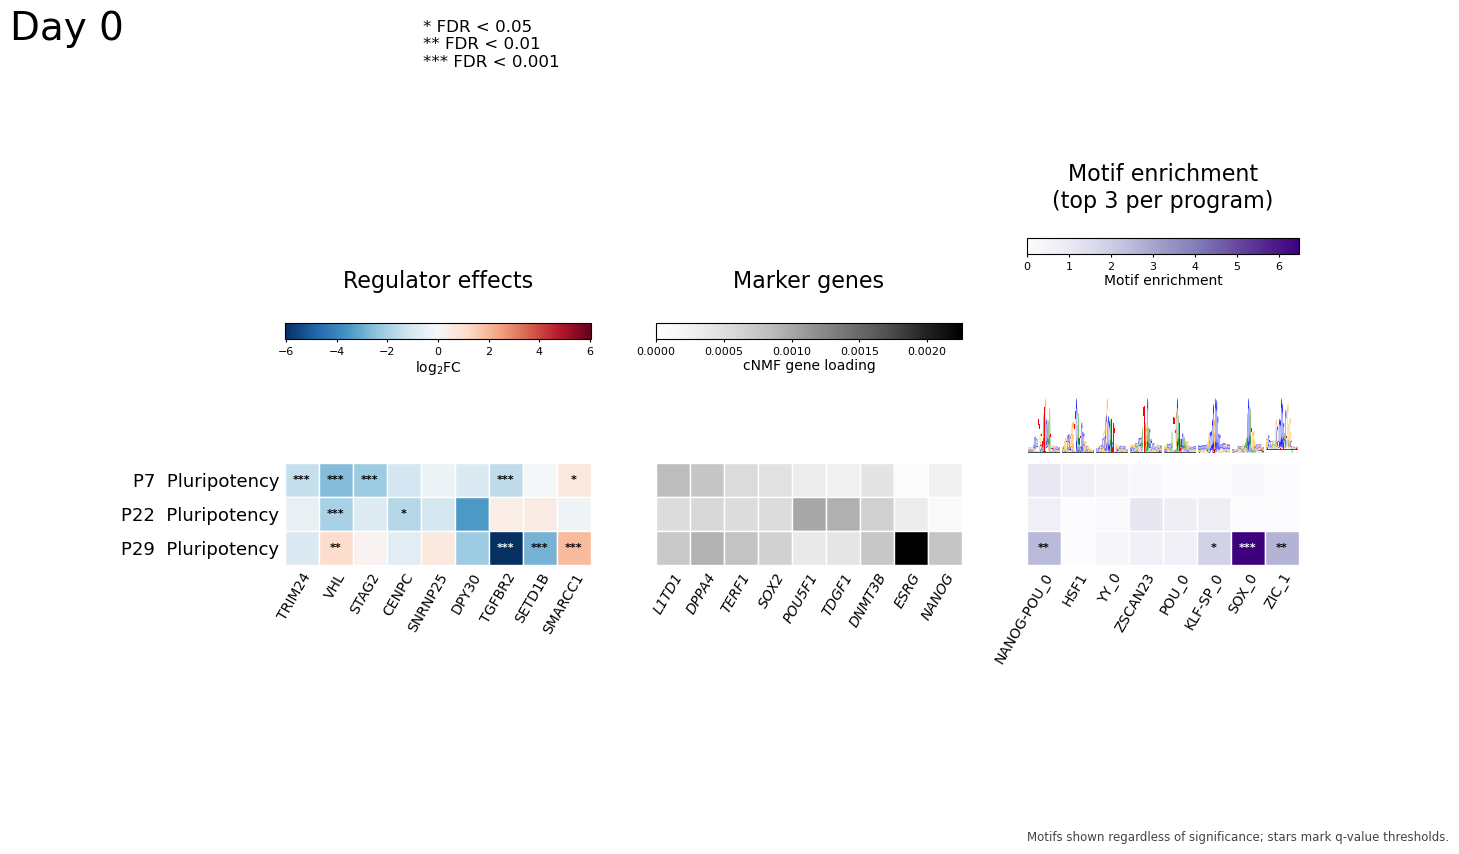

Saved D0 panel to:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D0.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D0.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D0.png


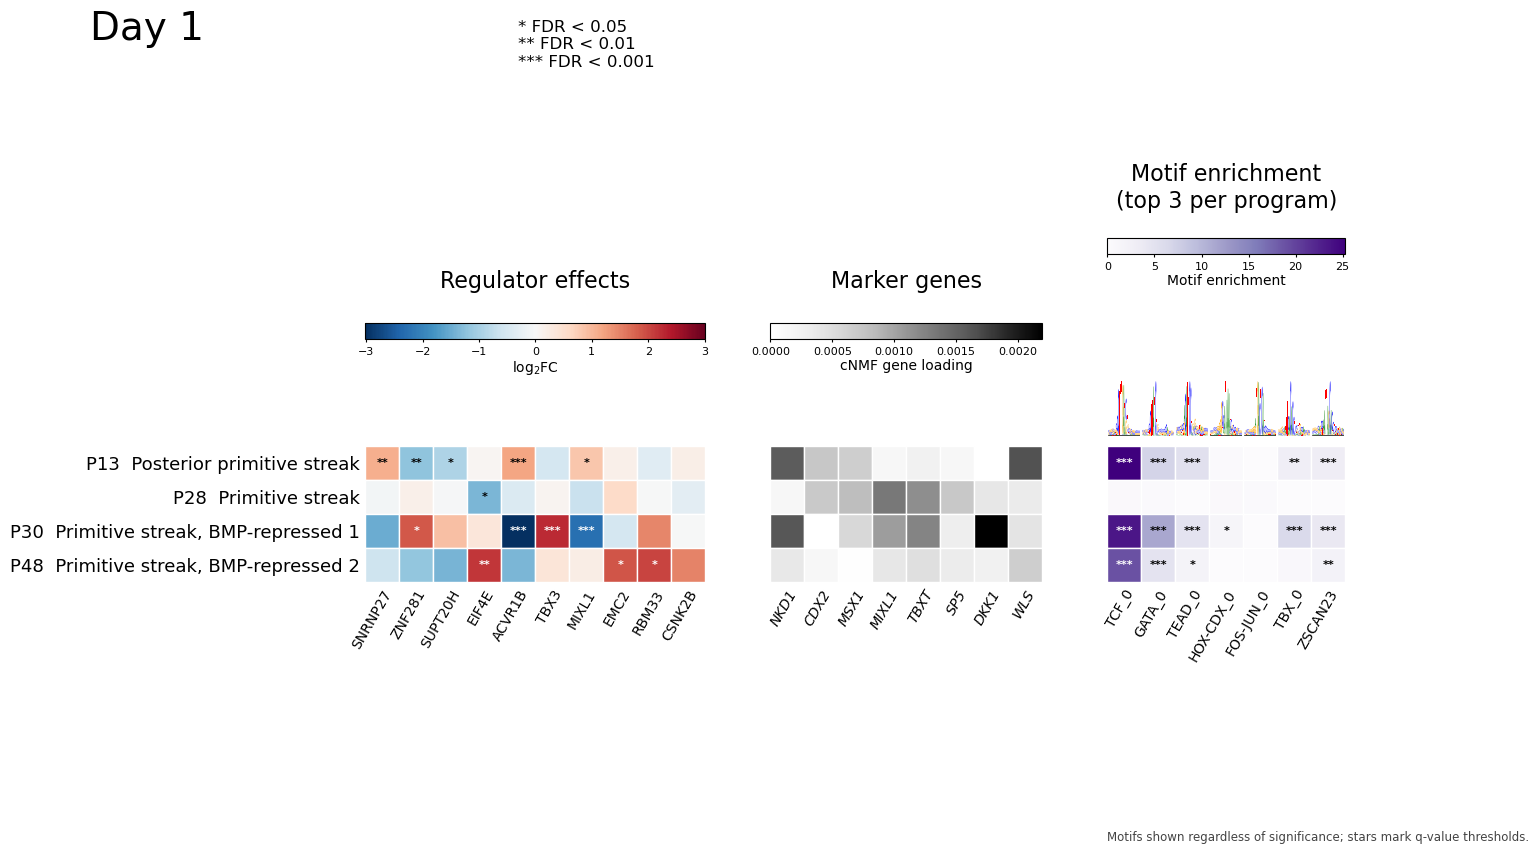

Saved D1 panel to:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D1.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D1.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D1.png


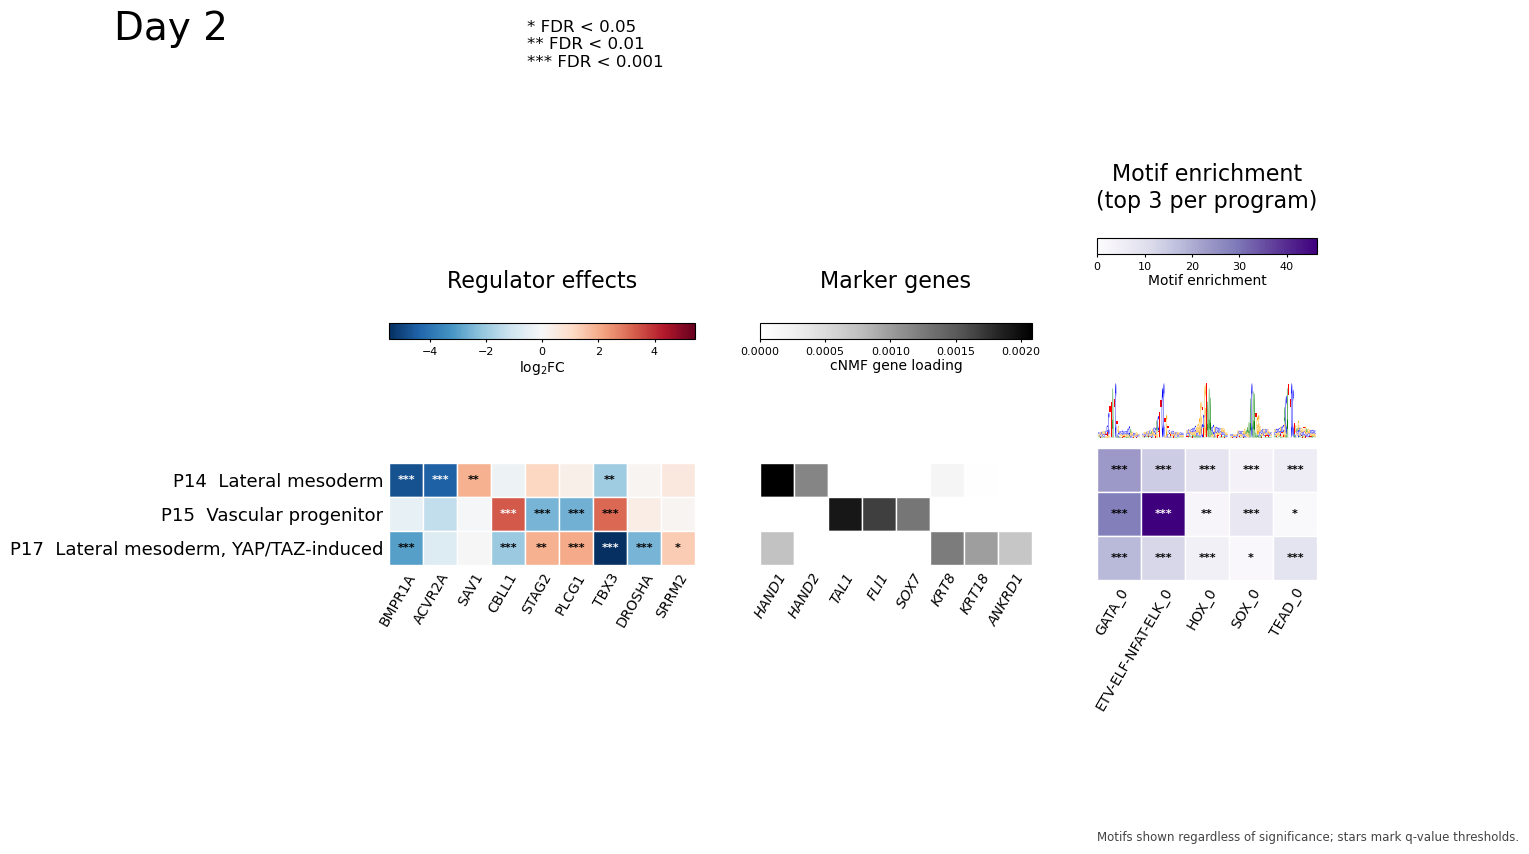

Saved D2 panel to:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D2.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D2.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D2.png


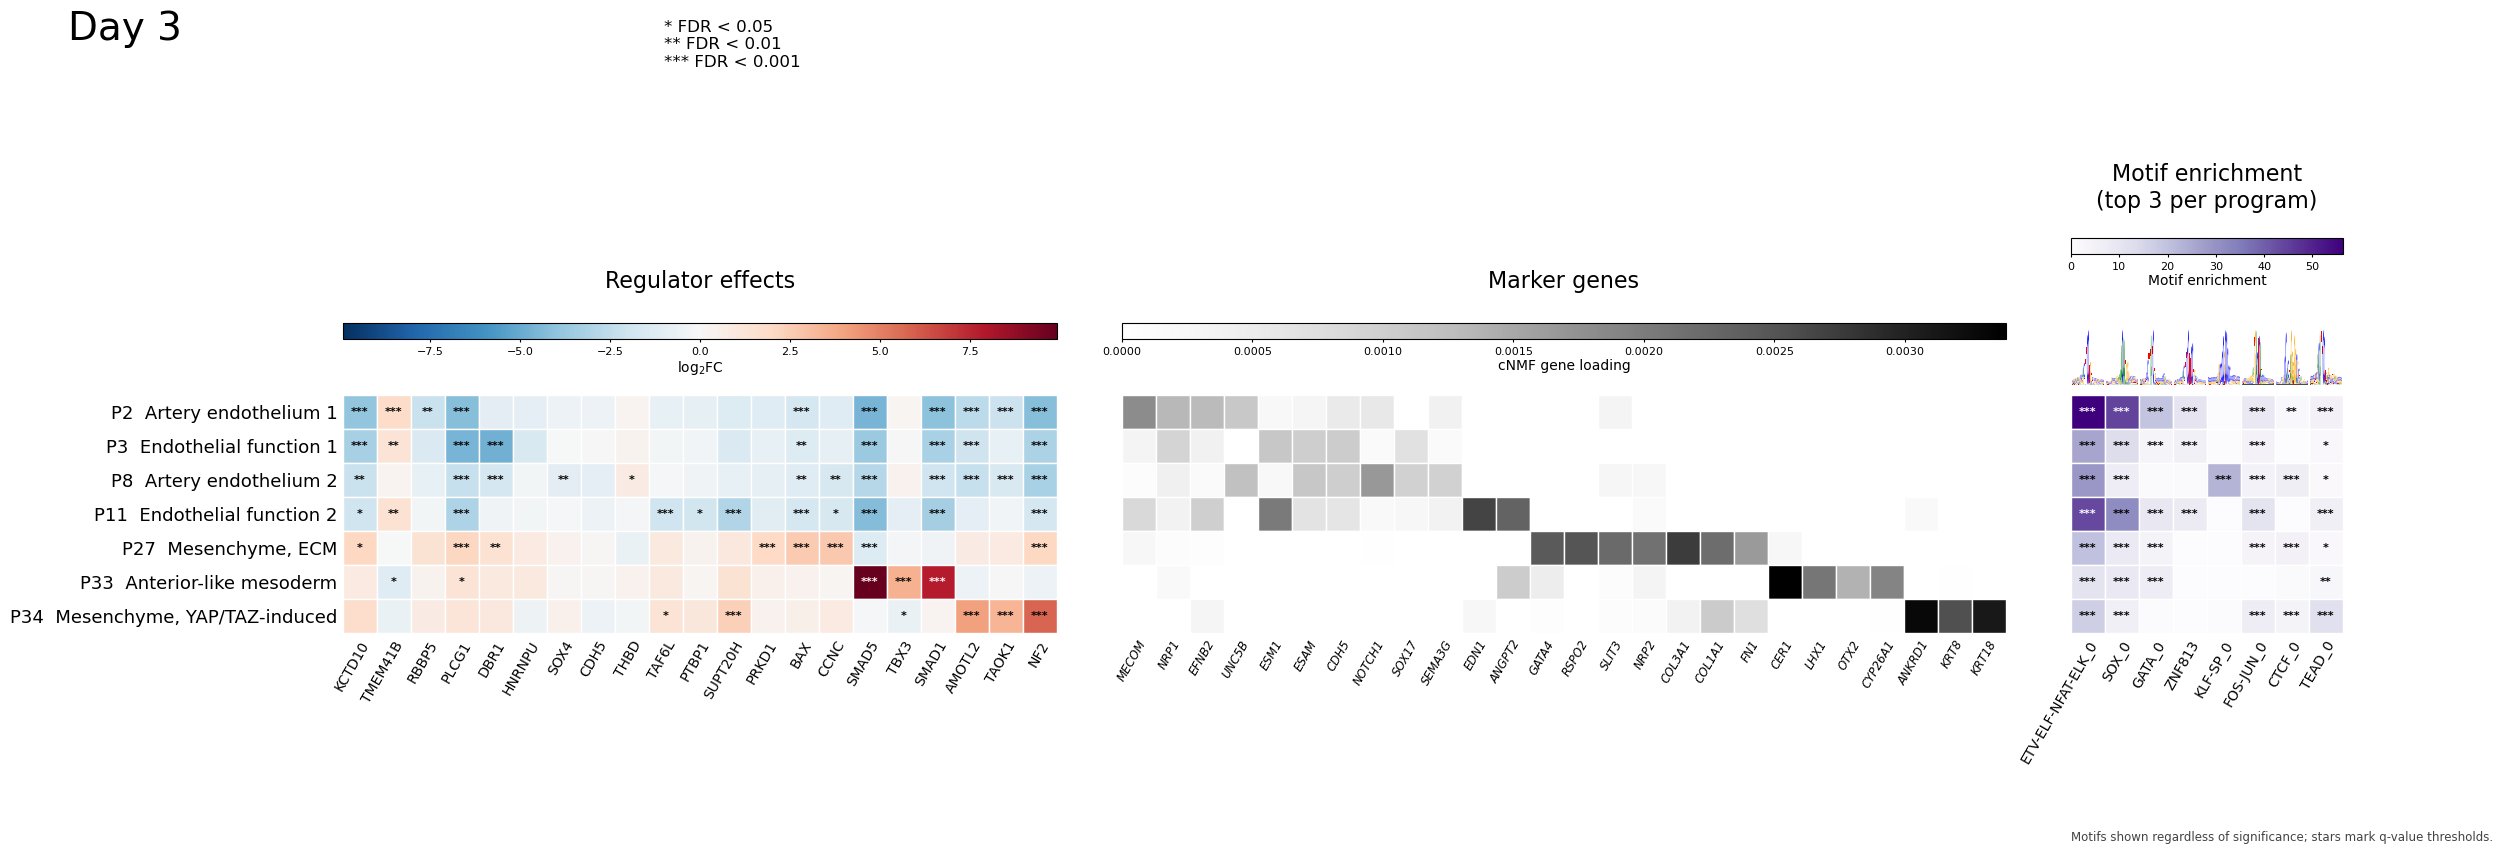

Saved D3 panel to:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D3.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D3.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D3.png


In [6]:

# ============================================================
# RENDER DAY 2 AND DAY 3 PANELS
# ============================================================

for day in DAYS_TO_PLOT:
    if day not in day_packages:
        print(f"[skip] {day}: no package")
        continue

    pkg = day_packages[day]

    outstem = make_day_panel(
        day=day,
        program_meta_day=pkg["meta"],
        regulator_effects=pkg["reg_effect_mat"],
        regulator_stars=pkg["reg_star_mat"],
        marker_loadings=pkg["marker_loading_mat"],
        motif_values=pkg["motif_value_mat"],
        motif_stars=pkg["motif_star_mat"],
        motif_to_logo=pkg["motif_to_logo"],
        regulator_union=pkg["reg_union"],
        marker_union=pkg["marker_union"],
        motif_union=pkg["motif_union"],
    )

    print(f"Saved {day} panel to:")
    print(" ", outstem.with_suffix(".svg"))
    print(" ", outstem.with_suffix(".pdf"))
    print(" ", outstem.with_suffix(".png"))
